# Module 5 — Notebook 06: Kinchen mouse arm (DSS) + cross-species scoring

The same GEO series (GSE114374) carries mouse healthy and DSS colon from the
same lab and pipeline. Kinchen's own cross-species claim: DSS induces Il11+
inflammatory fibroblasts in mouse colon, mirroring human UC. We test the
module's program-level conservation:

1. Load mouse HC + DSS matrices (same format as the human files).
2. Cluster; find the fibroblast compartment (Col1a1 rule).
3. Score the HUMAN inflammatory-fibroblast program in mouse fibroblasts using
   mouse ortholog symbols (program-level scoring — matrices are never merged
   across species).
4. Readout: does an Il11/Chi3l1-high fibroblast state expand in DSS, and where
   do Osm / Osmr / Sigirr sit?

Analyses of public datasets; all data credited to original authors.


In [1]:
import os, gzip
import numpy as np
import pandas as pd

base = os.path.expanduser("~/Documents/immune-endotypes/data/kinchen_2018")
FILES = {"Healthy": "GSE114374_Mouse_HC_expression_matrix.txt.gz",
         "DSS": "GSE114374_Mouse_DSS_expression_matrix.txt.gz"}
for cond, fn in FILES.items():
    print(cond, os.path.exists(os.path.join(base, fn)))


Healthy True
DSS True


In [3]:
# PEEK — same inspection as the human notebook: orientation + value type
with gzip.open(os.path.join(base, FILES["Healthy"]), "rt") as fh:
    peek = pd.read_csv(fh, sep="\t", index_col=0, nrows=2000)
print("peek shape (rows x cols):", peek.shape)
print("index head:", list(peek.index[:5]))
print("columns head:", list(peek.columns[:3]))
vals = peek.values
print("value range:", np.nanmin(vals), "->", np.nanmax(vals))
print("non-integer share:", float(np.mean(np.abs(vals - np.round(vals)) > 1e-9)))


peek shape (rows x cols): (2000, 3760)
index head: ['Xkr4', 'Gm1992', 'Gm37381', 'Rp1', 'Rp1.1']
columns head: ['AAACCTGAGTTAACGA-1', 'AAACGGGAGAAACCGC-1', 'AAACGGGCAAAGCAAT-1']
value range: 0.0 -> 5.77845555962295
non-integer share: 0.07864601063829788


Expected: rows = mouse gene symbols (Il11-style capitalization), columns =
cells; values pre-normalized like the human matrices. If the peek disagrees,
stop and show it before running the loader.


In [4]:
import scanpy as sc
import scipy.sparse as sp

def load_matrix(path, condition):
    chunks = []
    with gzip.open(path, "rt") as fh:
        for ch in pd.read_csv(fh, sep="\t", index_col=0, chunksize=2000):
            chunks.append(ch)
    df = pd.concat(chunks, axis=0)
    X = sp.csr_matrix(df.values.T)  # cells x genes
    ad = sc.AnnData(X)
    ad.obs_names = [str(c) for c in df.columns]
    ad.var_names = [str(g) for g in df.index]
    ad.obs["condition"] = condition
    ad.obs["sample"] = [c.rsplit("-", 1)[-1] for c in ad.obs_names]
    ad.obs["dataset"] = "KinchenMouse"
    return ad

ads = []
for cond, fn in FILES.items():
    a = load_matrix(os.path.join(base, fn), cond)
    print(cond, a.shape)
    ads.append(a)
adata = sc.concat(ads, join="outer")
adata.obs_names_make_unique()
adata.var_names_make_unique()
print(adata)
print(adata.obs["condition"].value_counts())


Healthy (3760, 28000)
DSS (3491, 15968)
AnnData object with n_obs × n_vars = 7251 × 28000
    obs: 'condition', 'sample', 'dataset'
condition
Healthy    3760
DSS        3491
Name: count, dtype: int64


/Users/juehuayu/miniconda3/envs/endotypes/lib/python3.11/site-packages/anndata/_core/anndata.py:1756: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


max value: 8.57 | integer-like fraction (first rows): 0.0
branch: pre-normalized values -> used as-is
after QC: (7248, 28000)


/Users/juehuayu/miniconda3/envs/endotypes/lib/python3.11/site-packages/pandas/core/util/hashing.py:330: RuntimeWarning: invalid value encountered in cast
  vals.astype(str).astype(object), hash_key, encoding
/Users/juehuayu/miniconda3/envs/endotypes/lib/python3.11/site-packages/pandas/core/util/hashing.py:330: RuntimeWarning: invalid value encountered in cast
  vals.astype(str).astype(object), hash_key, encoding
/Users/juehuayu/miniconda3/envs/endotypes/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/var/folders/l9/sgc71zs16rzd_nfvlhsbrkjc0000gn/T/ipykernel_3776/584998977.py:20: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igrap

leiden clusters: 14


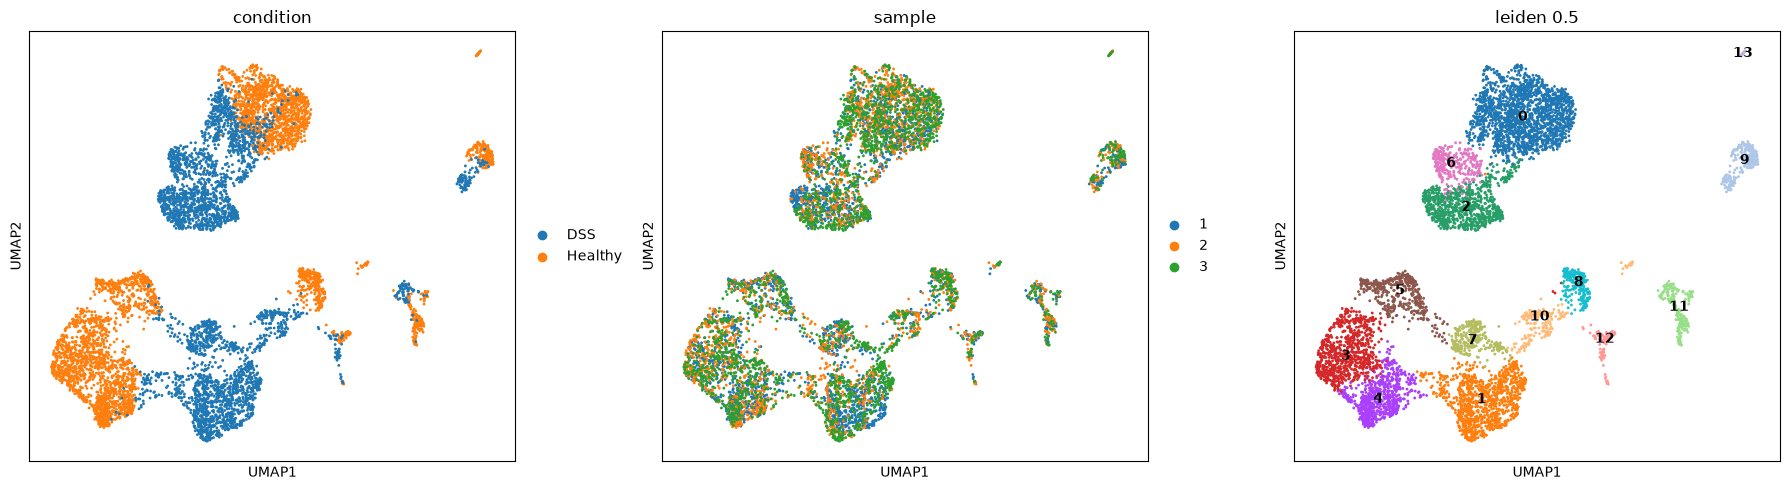

In [5]:
# Values branch + QC (same logic as human notebook 01)
vmax = float(adata.X.max())
frac_int = float((adata.X[:2000].data % 1 == 0).mean()) if sp.issparse(adata.X) else 0.0
print("max value:", round(vmax, 2), "| integer-like fraction (first rows):", round(frac_int, 3))
adata.var["mt"] = adata.var_names.str.startswith("mt-")
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], inplace=True, percent_top=None)
if vmax > 50 and frac_int > 0.99:
    adata.layers["counts"] = adata.X.copy()
    sc.pp.normalize_total(adata, target_sum=1e4)
    sc.pp.log1p(adata)
    print("branch: raw counts -> counts layer saved, normalized")
else:
    print("branch: pre-normalized values -> used as-is")
adata = adata[adata.obs["n_genes_by_counts"] > 200].copy()
print("after QC:", adata.shape)
sc.pp.highly_variable_genes(adata, n_top_genes=3000, batch_key="condition")
sc.tl.pca(adata, n_comps=50)
sc.pp.neighbors(adata, n_pcs=40)
sc.tl.umap(adata)
sc.tl.leiden(adata, resolution=0.5, key_added="leiden_0.5")
print("leiden clusters:", adata.obs["leiden_0.5"].nunique())
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sc.pl.umap(adata, color="condition", ax=axes[0], show=False, title="condition")
sc.pl.umap(adata, color="sample", ax=axes[1], show=False, title="sample")
sc.pl.umap(adata, color="leiden_0.5", ax=axes[2], show=False, title="leiden 0.5", legend_loc="on data")
plt.tight_layout(); plt.savefig("../figures/kinchen_mouse_umap_overview.png", dpi=130); plt.show()


markers present: ['Epcam', 'Col1a1', 'Dcn', 'Pecam1', 'Ptprc', 'Cd3d', 'Ms4a1', 'Jchain', 'Lyz2', 'S100a8']


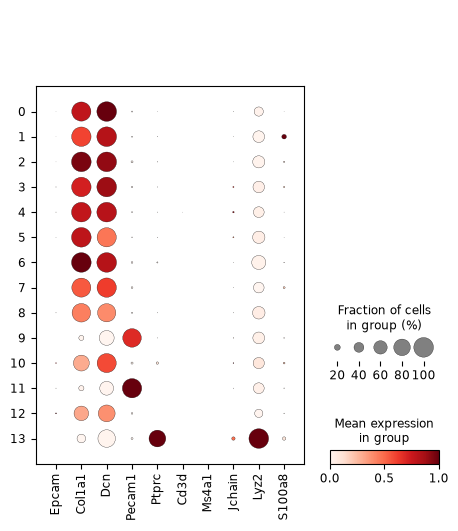

watch present: ['Il11', 'Il13ra2', 'Osmr', 'Osm', 'Sigirr', 'Il1b', 'Il1r1', 'Mmp3']


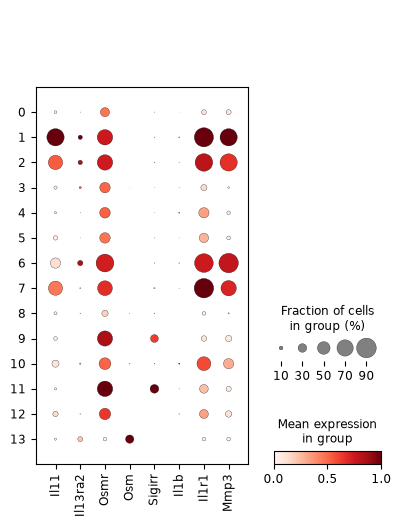

In [6]:
markers = ["Epcam", "Col1a1", "Dcn", "Pecam1", "Ptprc", "Cd3d", "Ms4a1", "Jchain", "Lyz2", "S100a8"]
present = [g for g in markers if g in adata.var_names]
print("markers present:", present)
sc.pl.dotplot(adata, present, groupby="leiden_0.5", standard_scale="var")
watch = ["Il11", "Il13ra2", "Chi3l1", "Osmr", "Osm", "Sigirr", "Il1b", "Il1r1", "Mmp3"]
watch = [g for g in watch if g in adata.var_names]
print("watch present:", watch)
sc.pl.dotplot(adata, watch, groupby="leiden_0.5", standard_scale="var")


In [7]:
# Cross-species program scoring in fibroblasts (Col1a1-fraction cluster rule)
adata.obs["_c"] = np.asarray((adata[:, "Col1a1"].X > 0).todense()).ravel() if sp.issparse(adata.X) else np.asarray(adata[:, "Col1a1"].X).ravel() > 0
fc = adata.obs.groupby("leiden_0.5")["_c"].mean() > 0.5
fib = adata[adata.obs["leiden_0.5"].isin(list(fc[fc].index))].copy()
print("fibroblast cells:", fib.shape, dict(fib.obs["condition"].value_counts()))
prog_mouse = ["Il11", "Il13ra2", "Il24", "Chi3l1", "Mmp3", "Mmp10", "Il6", "Cxcl1", "Cxcl5"]
prog_mouse = [g for g in prog_mouse if g in fib.var_names]
print("program genes present (mouse symbols):", prog_mouse)
sc.tl.score_genes(fib, prog_mouse, score_name="infl_fib_score_mouse")
print(fib.obs.groupby(["leiden_0.5", "condition"])["infl_fib_score_mouse"].mean().unstack().round(3))
ctf = pd.crosstab(fib.obs["leiden_0.5"], fib.obs["condition"], normalize="columns").round(3)
print(ctf)
adata.write(os.path.join(base, "adata_kinchen_mouse_qc.h5ad"))
print("saved adata_kinchen_mouse_qc.h5ad")


/var/folders/l9/sgc71zs16rzd_nfvlhsbrkjc0000gn/T/ipykernel_3776/4110161009.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  fc = adata.obs.groupby("leiden_0.5")["_c"].mean() > 0.5


fibroblast cells: (6777, 28000) {'Healthy': 3438, 'DSS': 3339}
program genes present (mouse symbols): ['Il11', 'Il13ra2', 'Il24', 'Mmp3', 'Mmp10', 'Il6', 'Cxcl1', 'Cxcl5']


/var/folders/l9/sgc71zs16rzd_nfvlhsbrkjc0000gn/T/ipykernel_3776/4110161009.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(fib.obs.groupby(["leiden_0.5", "condition"])["infl_fib_score_mouse"].mean().unstack().round(3))


condition     DSS  Healthy
leiden_0.5                
0           0.329    0.172
1           1.043      NaN
2           1.053      NaN
3             NaN   -0.008
4           0.039    0.027
5          -0.070   -0.054
6           0.829      NaN
7           0.546      NaN
8          -0.030   -0.254
10          0.214   -0.257
12          0.927    0.152
condition     DSS  Healthy
leiden_0.5                
0           0.161    0.373
1           0.311    0.000
2           0.249    0.000
3           0.000    0.232
4           0.016    0.191
5           0.011    0.111
6           0.091    0.000
7           0.087    0.000
8           0.001    0.068
10          0.058    0.007
12          0.014    0.017
saved adata_kinchen_mouse_qc.h5ad


## Read-out (fill in after running)

- Fibroblast clusters: which carry Il11 / Chi3l1, and are they DSS-expanded
  (composition table + program score by cluster x condition)?
- Osm source and Osmr target placement vs the human circuit?
- Verdict sentence for the paper: is the inflammatory-fibroblast program
  conserved in mouse DSS at program level?
- Next: cross-cohort summary figure (exact numbers from all saved objects),
  then the manuscript draft.
